In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
!gdown 1CgBW5H54YfdYtJmYE5GWctaHZSpFt71V

Downloading...
From: https://drive.google.com/uc?id=1CgBW5H54YfdYtJmYE5GWctaHZSpFt71V
To: /content/spam_ham_dataset.csv
100% 5.50M/5.50M [00:00<00:00, 53.7MB/s]


In [ ]:
demo1 = pd.read_csv('spam_ham_dataset.csv')
demo1.drop(['Unnamed: 0','label'],axis=1,inplace=True)
demo1.head()

,text,label_num
0,Subject: enron methanol ; meter # : 988291\r\n...,0
1,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,"Subject: photoshop , windows , office . cheap ...",1
4,Subject: re : indian springs\r\nthis deal is t...,0


In [ ]:
!gdown 1dw56R8SzKgTgiKurfBLUTxmiewJacMkt

Downloading...
From: https://drive.google.com/uc?id=1dw56R8SzKgTgiKurfBLUTxmiewJacMkt
To: /content/Spam_finalData.csv
100% 1.64M/1.64M [00:00<00:00, 37.8MB/s]


In [ ]:
dt = pd.read_csv('Spam_finalData.csv')

In [ ]:
dt.head()

,label_num,Feature0,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10,Feature11,Feature12,Feature13,Feature14
0,0,-0.031489,-0.003323,-0.071238,0.047743,0.060798,0.046597,-0.069530,-0.000031,-0.037924,0.024059,-0.015085,-0.007752,-0.021617,-0.025395,0.046050
1,0,-0.122601,0.114176,0.460451,0.000953,0.014707,0.007610,-0.011173,-0.052478,0.040209,0.000076,0.010306,0.023397,-0.007294,0.063543,0.081119
2,0,-0.076681,-0.084330,-0.054658,-0.048236,-0.019999,-0.045909,-0.004712,-0.001524,0.013735,-0.022429,0.010273,-0.007458,-0.044340,-0.051093,0.025553
3,1,-0.075948,-0.059706,-0.025301,-0.037603,-0.001208,-0.030660,0.018873,-0.013434,-0.014981,0.000741,0.005653,0.032153,0.001884,-0.018005,-0.011060
4,0,-0.054680,0.033033,-0.090885,-0.047280,-0.029304,0.085893,-0.105351,-0.053915,-0.006857,0.021673,0.056718,0.006140,0.042217,0.018862,-0.007373


In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(dt.drop(['label_num'],axis=1),dt['label_num'])

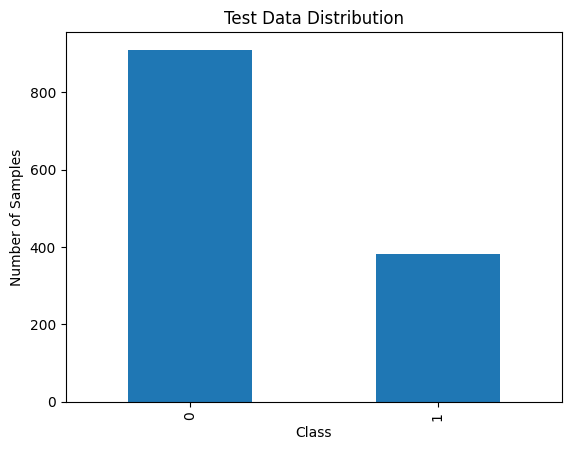

In [ ]:
y_test.value_counts().plot(kind='bar')
plt.xlabel('Class')
plt.ylabel('Number of Samples')
plt.title('Test Data Distribution')
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train,y_train)

LogisticRegression()

In [ ]:
model.score(X_test, y_test)

0.9296210363495746

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = model.predict(X_test)

conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix # 2D np array

array([[844,  66],
       [ 25, 358]])

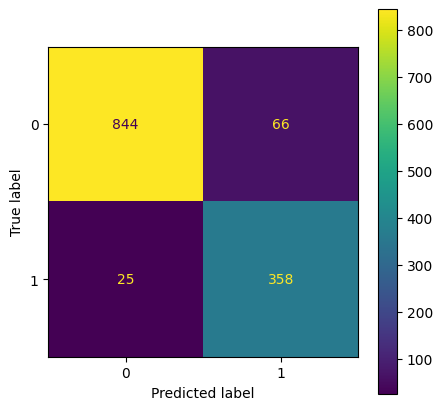

In [ ]:
# ax used here to control the size of confusion matrix
fig, ax = plt.subplots(figsize=(5,5))
ConfusionMatrixDisplay(conf_matrix).plot(ax = ax)

In [ ]:
np.diag(conf_matrix).sum() / conf_matrix.sum()

0.9296210363495746

In [ ]:
from sklearn.metrics import precision_score

precision_score(y_test, y_pred)


0.8443396226415094

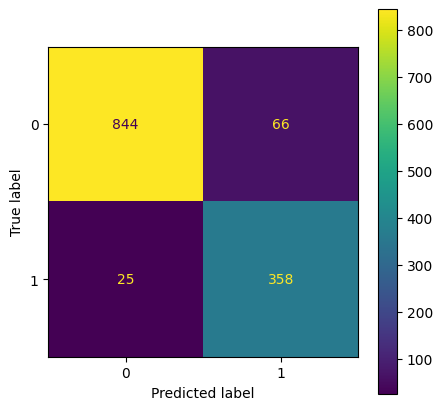

In [ ]:
# Recall Score

fig, ax = plt.subplots(figsize=(5,5))
ConfusionMatrixDisplay(conf_matrix).plot(ax = ax)

In [ ]:
from sklearn.metrics import recall_score

recall_score(y_test, y_pred)

0.9347258485639687

In [ ]:
from sklearn.metrics import f1_score

In [ ]:
print(f'f1Score:{f1_score(y_test,y_pred)}')

f1Score:0.8872366790582404


In [ ]:
# ROC

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

In [ ]:
probability = model.predict_proba(X_test)
probability

array([[0.97641233, 0.02358767],
       [0.94421768, 0.05578232],
       [0.9916738 , 0.0083262 ],
       ...,
       [0.3871405 , 0.6128595 ],
       [0.33717726, 0.66282274],
       [0.96690028, 0.03309972]])

In [ ]:
probabilities = probability[:, 1]
probabilities[:5]

array([0.02358767, 0.05578232, 0.0083262 , 0.00370894, 0.04843852])

In [ ]:
fpr, tpr, thres = roc_curve(y_test, probabilities)

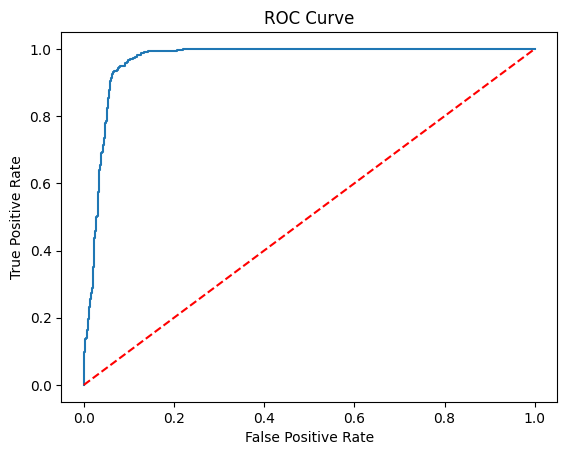

In [ ]:
plt.plot(fpr, tpr)
plt.plot([0,1],[0,1],linestyle='--', color='r')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.show()

In [ ]:
roc_auc_score(y_test, probabilities)

0.966852207844375

In [ ]:
probabilities[:5]

array([0.02358767, 0.05578232, 0.0083262 , 0.00370894, 0.04843852])

In [ ]:
new_probabilities = np.sqrt(probabilities)
new_probabilities[:5]

array([0.15358279, 0.23618281, 0.09124803, 0.0609011 , 0.22008753])

In [ ]:
fpr, tpr, thres = roc_curve(y_test, new_probabilities)

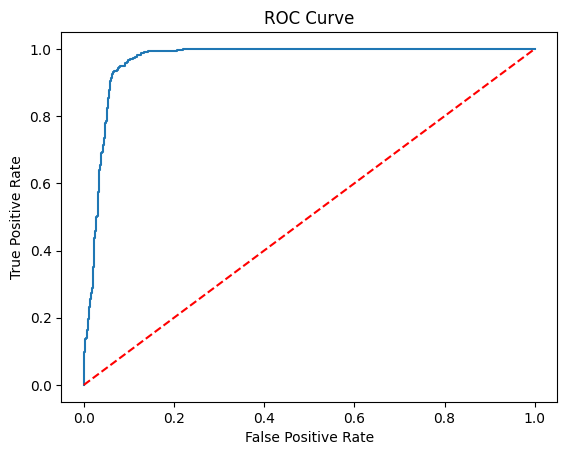

In [ ]:
plt.plot(fpr, tpr)
plt.plot([0,1],[0,1],linestyle='--', color='r')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.show()

In [ ]:
roc_auc_score(y_test, new_probabilities)

0.966852207844375

In [ ]:
from sklearn.metrics import precision_recall_curve, auc

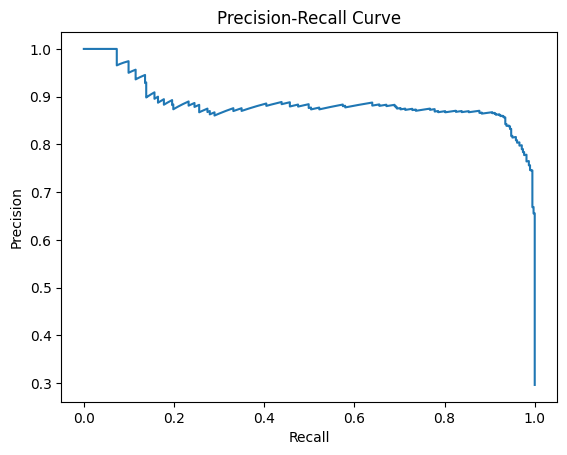

In [ ]:
precision, recall, thres = precision_recall_curve(y_test, probabilities)

plt.plot(recall, precision)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.show()

In [ ]:
auc(recall, precision)

0.8854422206299883

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from imblearn.over_sampling import SMOTE

# Create an instance of SMOTE
smt = SMOTE()

y_train.value_counts()

,count
label_num,
0,2762
1,1116


In [ ]:
X_sm, y_sm = smt.fit_resample(X_train, y_train)

In [ ]:
y_sm.value_counts()

,count
label_num,
0,2762
1,2762


In [ ]:
model = LogisticRegression(C=50, penalty='l2')

In [ ]:
model.fit(X_sm, y_sm)

LogisticRegression(C=50)

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
f1_score(y_test, y_pred)

0.9057971014492754